In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.14.1+cu130
GPU available: True
GPU: Tesla T4


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

drive_path = "/content/drive/MyDrive"

print("Files and folders in MyDrive:\n")

for item in os.listdir(drive_path):
    print(item)

Files and folders in MyDrive:

Colab Notebooks
StudentPerformanceFactors.csv
AI Semester Project
bills.pdf
Candidate and Father's Domicile  (1).pdf
Achievements .pdf
challans.pdf
cnic.pdf
Ubedullah-Rehan-Subhash_final_project
BrainScan
reseach papers
web
BrainTumorSegmentation
classification_task


In [ ]:
import os

dataset_path = "/content/drive/MyDrive/classification_task"

print("Dataset contents:\n")

for item in os.listdir(dataset_path):
    path = os.path.join(dataset_path, item)

    if os.path.isdir(path):
        print(f"[Folder] {item}")
    else:
        print(f"[File]   {item}")

Dataset contents:

[Folder] train
[Folder] test


In [ ]:
import os

for split in ["train", "test"]:
    split_path = os.path.join(dataset_path, split)

    print(f"\n{split.upper()}:")

    for class_name in os.listdir(split_path):
        class_path = os.path.join(split_path, class_name)

        if os.path.isdir(class_path):
            image_count = len(os.listdir(class_path))
            print(f"  {class_name}: {image_count} images")


TRAIN:
  pituitary: 1457 images
  no_tumor: 1067 images
  meningioma: 1329 images
  glioma: 1147 images

TEST:
  pituitary: 300 images
  meningioma: 306 images
  no_tumor: 140 images
  glioma: 254 images


In [ ]:
from pathlib import Path

CLASSES = ["glioma", "meningioma", "no_tumor", "pituitary"]

TRAIN_DIR = Path(dataset_path) / "train"
TEST_DIR = Path(dataset_path) / "test"

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

def get_image_files(directory):
    return sorted(
        path for path in directory.rglob("*")
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
    )

train_paths_original = get_image_files(TRAIN_DIR)
test_paths_original = get_image_files(TEST_DIR)

print("Original training images:", len(train_paths_original))
print("Original testing images:", len(test_paths_original))
print("Total images:", len(train_paths_original) + len(test_paths_original))

Original training images: 5000
Original testing images: 1000
Total images: 6000


In [ ]:
import shutil
from pathlib import Path

local_dataset_path = Path("/content/classification_task")

if not local_dataset_path.exists():
    print("Copying dataset from Google Drive to Colab storage...")
    shutil.copytree(dataset_path, local_dataset_path)
    print("Dataset copy completed!")
else:
    print("Dataset already exists in local storage.")

print("Local dataset path:", local_dataset_path)

Copying dataset from Google Drive to Colab storage...
Dataset copy completed!
Local dataset path: /content/classification_task


In [ ]:
import hashlib
from PIL import Image
from collections import defaultdict

def calculate_image_hash(image_path):
    with Image.open(image_path) as image:
        grayscale = image.convert("L")

        image_bytes = (
            str(grayscale.size).encode()
            + grayscale.tobytes()
        )

        return hashlib.sha256(image_bytes).hexdigest()


print("Calculating image hashes...")

train_hashes = {
    path: calculate_image_hash(path)
    for path in train_paths_original
}

test_hashes = {
    path: calculate_image_hash(path)
    for path in test_paths_original
}

# Identify hashes shared between train and test
test_hash_set = set(test_hashes.values())

cross_split_hashes = {
    train_hashes[path]
    for path in train_paths_original
    if train_hashes[path] in test_hash_set
}

# Remove training images that have exact copies in test
train_paths_clean = [
    path for path in train_paths_original
    if train_hashes[path] not in test_hash_set
]

# Remove redundant exact duplicates within training
hash_to_paths = defaultdict(list)

for path in train_paths_clean:
    hash_to_paths[train_hashes[path]].append(path)

train_paths_final = [
    paths[0]
    for paths in hash_to_paths.values()
]

# Keep test dataset unchanged
test_paths_final = test_paths_original.copy()

print("\n" + "=" * 45)
print("CLEANING RESULTS")
print("=" * 45)

print("Original training images:", len(train_paths_original))
print("Cross-split duplicate groups:", len(cross_split_hashes))
print("Training images removed due to leakage:",
      len(train_paths_original) - len(train_paths_clean))
print("Within-training duplicate groups:",
      sum(1 for paths in hash_to_paths.values() if len(paths) > 1))
print("Within-training redundant copies removed:",
      len(train_paths_clean) - len(train_paths_final))
print("Final cleaned training images:", len(train_paths_final))
print("Testing images:", len(test_paths_final))

Calculating image hashes...

CLEANING RESULTS
Original training images: 5000
Cross-split duplicate groups: 98
Training images removed due to leakage: 104
Within-training duplicate groups: 31
Within-training redundant copies removed: 32
Final cleaned training images: 4864
Testing images: 1000


In [ ]:
from sklearn.model_selection import train_test_split

# Extract labels from folder names
train_labels = [path.parent.name for path in train_paths_final]

# Stratified 80/20 split
train_paths, val_paths, train_labels, val_labels = train_test_split(
    train_paths_final,
    train_labels,
    test_size=0.20,
    random_state=42,
    stratify=train_labels
)

# Test dataset remains untouched
test_paths = test_paths_final

print("Dataset Split Results")
print("=" * 40)
print(f"Training:   {len(train_paths)}")
print(f"Validation: {len(val_paths)}")
print(f"Testing:    {len(test_paths)}")
print(f"Total:      {len(train_paths) + len(val_paths) + len(test_paths)}")

Dataset Split Results
Training:   3891
Validation: 973
Testing:    1000
Total:      5864


In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

# Consistent class mapping
CLASSES = ["glioma", "meningioma", "no_tumor", "pituitary"]

class_to_idx = {
    class_name: idx
    for idx, class_name in enumerate(CLASSES)
}

print("Class mapping:", class_to_idx)

# Training transformations (augmentation included)
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ToTensor()
])

# Validation and testing transformations (no augmentation)
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])


class BrainTumorDataset(Dataset):
    def __init__(self, image_paths, transform=None):
        self.image_paths = image_paths
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image_path = self.image_paths[idx]

        image = Image.open(image_path).convert("RGB")
        label = class_to_idx[image_path.parent.name]

        if self.transform:
            image = self.transform(image)

        return image, label


# Create datasets
train_dataset = BrainTumorDataset(
    train_paths,
    transform=train_transform
)

val_dataset = BrainTumorDataset(
    val_paths,
    transform=eval_transform
)

test_dataset = BrainTumorDataset(
    test_paths,
    transform=eval_transform
)

print("\nDatasets created successfully!")
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))

Class mapping: {'glioma': 0, 'meningioma': 1, 'no_tumor': 2, 'pituitary': 3}

Datasets created successfully!
Training samples: 3891
Validation samples: 973
Testing samples: 1000


In [ ]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("DataLoaders created successfully!")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

DataLoaders created successfully!
Training batches: 122
Validation batches: 31
Testing batches: 32


In [ ]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Labels in this batch:", labels)
print("Image dtype:", images.dtype)
print("Pixel range:", images.min().item(), "to", images.max().item())

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Labels in this batch: tensor([3, 3, 1, 3, 1, 3, 3, 2, 1, 1, 0, 3, 2, 3, 1, 1, 1, 0, 2, 2, 2, 1, 0, 3,
        2, 1, 3, 1, 0, 0, 0, 0])
Image dtype: torch.float32
Pixel range: 0.0 to 0.95686274766922


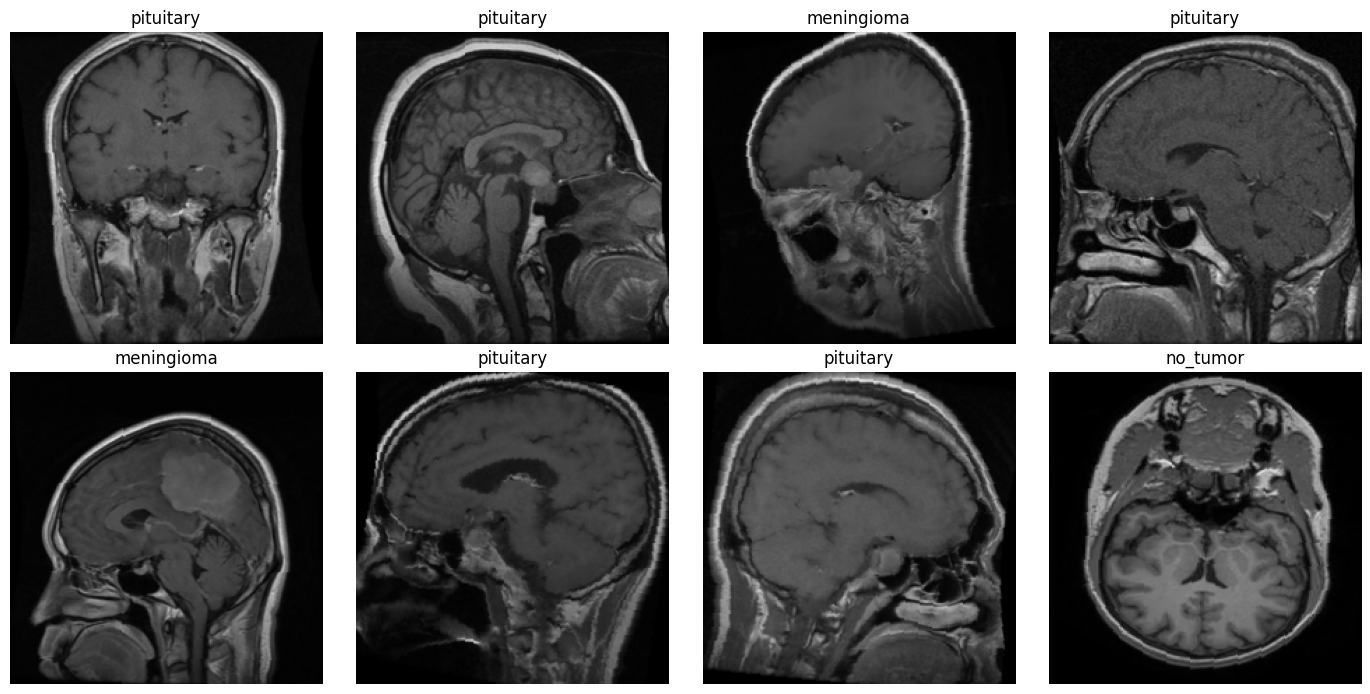

In [ ]:
import matplotlib.pyplot as plt

idx_to_class = {idx: name for name, idx in class_to_idx.items()}

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for i, ax in enumerate(axes.flat):
    image = images[i].permute(1, 2, 0).numpy()
    label = labels[i].item()

    ax.imshow(image)
    ax.set_title(idx_to_class[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from torchvision import transforms
from torch.utils.data import DataLoader

# ImageNet normalization
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

feature_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=imagenet_mean,
        std=imagenet_std
    )
])

# Recreate datasets with ResNet-compatible preprocessing
train_dataset = BrainTumorDataset(
    train_paths,
    transform=feature_transform
)

val_dataset = BrainTumorDataset(
    val_paths,
    transform=feature_transform
)

test_dataset = BrainTumorDataset(
    test_paths,
    transform=feature_transform
)

# Create loaders
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("ResNet50 preprocessing configured!")
print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

ResNet50 preprocessing configured!
Train: 3891
Validation: 973
Test: 1000


In [ ]:
import torch
import torch.nn as nn
from torchvision.models import resnet50, ResNet50_Weights

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load pretrained ResNet50
weights = ResNet50_Weights.DEFAULT
resnet_model = resnet50(weights=weights)

# Remove the final classification layer
resnet_model.fc = nn.Identity()

# Move model to GPU
resnet_model = resnet_model.to(device)

# Set to evaluation mode
resnet_model.eval()

print("ResNet50 loaded successfully!")
print("Device:", device)
print("Feature extractor output size: 2048")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 73.4MB/s]


ResNet50 loaded successfully!
Device: cuda
Feature extractor output size: 2048


In [ ]:
images, labels = next(iter(train_loader))

images = images.to(device)

with torch.no_grad():
    features = resnet_model(images)

print("Input batch shape:", images.shape)
print("Extracted feature shape:", features.shape)
print("Feature dtype:", features.dtype)

Input batch shape: torch.Size([32, 3, 224, 224])
Extracted feature shape: torch.Size([32, 2048])
Feature dtype: torch.float32


In [ ]:
import numpy as np
from tqdm.auto import tqdm
import os

def extract_features(model, loader, device):
    all_features = []
    all_labels = []

    model.eval()

    with torch.no_grad():
        for images, labels in tqdm(loader):
            images = images.to(device)

            features = model(images)

            all_features.append(features.cpu().numpy())
            all_labels.append(labels.numpy())

    X = np.concatenate(all_features, axis=0)
    y = np.concatenate(all_labels, axis=0)

    return X, y


# Extract features from each split
print("Extracting training features...")
X_train_resnet, y_train = extract_features(
    resnet_model, train_loader, device
)

print("\nExtracting validation features...")
X_val_resnet, y_val = extract_features(
    resnet_model, val_loader, device
)

print("\nExtracting test features...")
X_test_resnet, y_test = extract_features(
    resnet_model, test_loader, device
)


# Verify shapes
print("\nFeature Extraction Completed!")
print("=" * 45)

print("Training features:", X_train_resnet.shape)
print("Training labels:", y_train.shape)

print("Validation features:", X_val_resnet.shape)
print("Validation labels:", y_val.shape)

print("Testing features:", X_test_resnet.shape)
print("Testing labels:", y_test.shape)

Extracting training features...


  0%|          | 0/122 [00:00<?, ?it/s]


Extracting validation features...


  0%|          | 0/31 [00:00<?, ?it/s]


Extracting test features...


  0%|          | 0/32 [00:00<?, ?it/s]


Feature Extraction Completed!
Training features: (3891, 2048)
Training labels: (3891,)
Validation features: (973, 2048)
Validation labels: (973,)
Testing features: (1000, 2048)
Testing labels: (1000,)


In [ ]:
import numpy as np
from pathlib import Path

# Create directory in Google Drive
feature_dir = Path("/content/drive/MyDrive/BrainTumorClassification/features")
feature_dir.mkdir(parents=True, exist_ok=True)

# Save ResNet50 extracted features
feature_file = feature_dir / "resnet50_features.npz"

np.savez_compressed(
    feature_file,
    X_train=X_train_resnet,
    y_train=y_train,
    X_val=X_val_resnet,
    y_val=y_val,
    X_test=X_test_resnet,
    y_test=y_test,
    classes=np.array(CLASSES)
)

print("Features saved successfully!")
print("Location:", feature_file)
print("File size:", round(feature_file.stat().st_size / (1024**2), 2), "MB")

Features saved successfully!
Location: /content/drive/MyDrive/BrainTumorClassification/features/resnet50_features.npz
File size: 28.69 MB


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Build the pipeline
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale"
    ))
])

# Train using extracted training features
print("Training ResNet50 + SVM...")

svm_model.fit(X_train_resnet, y_train)

print("Training completed!")

Training ResNet50 + SVM...
Training completed!


In [ ]:
# Predict validation labels
y_val_pred = svm_model.predict(X_val_resnet)

# Calculate validation accuracy
val_accuracy = accuracy_score(y_val, y_val_pred)

print("Validation Accuracy:", round(val_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred,
    target_names=CLASSES
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred))

Validation Accuracy: 93.01 %

Classification Report:
              precision    recall  f1-score   support

      glioma       0.97      0.84      0.90       229
  meningioma       0.84      0.92      0.88       244
    no_tumor       0.98      0.99      0.98       212
   pituitary       0.95      0.97      0.96       288

    accuracy                           0.93       973
   macro avg       0.94      0.93      0.93       973
weighted avg       0.93      0.93      0.93       973


Confusion Matrix:
[[193  35   0   1]
 [  4 224   2  14]
 [  1   2 209   0]
 [  0   7   2 279]]


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

C_values = [0.1, 1, 10, 100]
gamma_values = ["scale", "auto"]

results = []

for C in C_values:
    for gamma in gamma_values:

        model = Pipeline([
            ("scaler", StandardScaler()),
            ("classifier", SVC(
                kernel="rbf",
                C=C,
                gamma=gamma
            ))
        ])

        model.fit(X_train_resnet, y_train)

        predictions = model.predict(X_val_resnet)

        accuracy = accuracy_score(y_val, predictions)

        results.append({
            "C": C,
            "gamma": gamma,
            "accuracy": accuracy
        })

        print(f"C={C}, gamma={gamma}, Accuracy={accuracy:.4f}")

C=0.1, gamma=scale, Accuracy=0.8253
C=0.1, gamma=auto, Accuracy=0.8253
C=1, gamma=scale, Accuracy=0.9301
C=1, gamma=auto, Accuracy=0.9301
C=10, gamma=scale, Accuracy=0.9507
C=10, gamma=auto, Accuracy=0.9507
C=100, gamma=scale, Accuracy=0.9507
C=100, gamma=auto, Accuracy=0.9507


In [ ]:
# Cell: Train the best SVM configuration and evaluate it on validation data

best_svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(kernel="rbf", C=10, gamma="scale"))
])

best_svm_model.fit(X_train_resnet, y_train)

y_val_pred_best = best_svm_model.predict(X_val_resnet)

print("Best SVM Validation Accuracy:",
      round(accuracy_score(y_val, y_val_pred_best) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_best, target_names=CLASSES))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_best))

Best SVM Validation Accuracy: 95.07 %

Classification Report:
              precision    recall  f1-score   support

      glioma       0.99      0.87      0.93       229
  meningioma       0.87      0.96      0.91       244
    no_tumor       0.99      0.99      0.99       212
   pituitary       0.97      0.98      0.98       288

    accuracy                           0.95       973
   macro avg       0.95      0.95      0.95       973
weighted avg       0.95      0.95      0.95       973


Confusion Matrix:
[[199  29   0   1]
 [  2 234   1   7]
 [  0   2 210   0]
 [  0   4   2 282]]


In [ ]:
# Cell: Train a Random Forest classifier on ResNet50 extracted features

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

print("Training ResNet50 + Random Forest...")

rf_model.fit(X_train_resnet, y_train)

print("Training completed!")

y_val_pred_rf = rf_model.predict(X_val_resnet)

print("\nValidation Accuracy:",
      round(accuracy_score(y_val, y_val_pred_rf) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_rf, target_names=CLASSES))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_rf))

Training ResNet50 + Random Forest...
Training completed!

Validation Accuracy: 88.49 %

Classification Report:
              precision    recall  f1-score   support

      glioma       0.95      0.78      0.86       229
  meningioma       0.81      0.82      0.82       244
    no_tumor       0.99      0.94      0.96       212
   pituitary       0.84      0.98      0.91       288

    accuracy                           0.88       973
   macro avg       0.90      0.88      0.89       973
weighted avg       0.89      0.88      0.88       973


Confusion Matrix:
[[179  40   1   9]
 [  7 201   2  34]
 [  1   3 199   9]
 [  1   5   0 282]]


In [ ]:
# Cell: Tune Random Forest hyperparameters using validation accuracy

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

n_estimators_values = [300, 500]
max_depth_values = [None, 20, 30]
min_samples_leaf_values = [1, 2]

rf_results = []

for n_estimators in n_estimators_values:
    for max_depth in max_depth_values:
        for min_samples_leaf in min_samples_leaf_values:

            model = RandomForestClassifier(
                n_estimators=n_estimators,
                max_depth=max_depth,
                min_samples_leaf=min_samples_leaf,
                random_state=42,
                n_jobs=-1
            )

            model.fit(X_train_resnet, y_train)

            predictions = model.predict(X_val_resnet)

            accuracy = accuracy_score(y_val, predictions)

            rf_results.append({
                "n_estimators": n_estimators,
                "max_depth": max_depth,
                "min_samples_leaf": min_samples_leaf,
                "accuracy": accuracy
            })

            print(
                f"Trees={n_estimators}, "
                f"Depth={max_depth}, "
                f"Leaf={min_samples_leaf}, "
                f"Accuracy={accuracy:.4f}"
            )

Trees=300, Depth=None, Leaf=1, Accuracy=0.8849
Trees=300, Depth=None, Leaf=2, Accuracy=0.8880
Trees=300, Depth=20, Leaf=1, Accuracy=0.8890
Trees=300, Depth=20, Leaf=2, Accuracy=0.8880
Trees=300, Depth=30, Leaf=1, Accuracy=0.8849
Trees=300, Depth=30, Leaf=2, Accuracy=0.8869
Trees=500, Depth=None, Leaf=1, Accuracy=0.8911
Trees=500, Depth=None, Leaf=2, Accuracy=0.8859
Trees=500, Depth=20, Leaf=1, Accuracy=0.8880
Trees=500, Depth=20, Leaf=2, Accuracy=0.8869
Trees=500, Depth=30, Leaf=1, Accuracy=0.8921
Trees=500, Depth=30, Leaf=2, Accuracy=0.8869


In [ ]:
# Cell: Train and evaluate the best tuned Random Forest configuration

best_rf_model = RandomForestClassifier(
    n_estimators=500,
    max_depth=30,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

best_rf_model.fit(X_train_resnet, y_train)

y_val_pred_rf_best = best_rf_model.predict(X_val_resnet)

print("Best Random Forest Validation Accuracy:",
      round(accuracy_score(y_val, y_val_pred_rf_best) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_rf_best, target_names=CLASSES))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_rf_best))

Best Random Forest Validation Accuracy: 89.21 %

Classification Report:
              precision    recall  f1-score   support

      glioma       0.95      0.80      0.87       229
  meningioma       0.82      0.84      0.83       244
    no_tumor       0.98      0.94      0.96       212
   pituitary       0.85      0.98      0.91       288

    accuracy                           0.89       973
   macro avg       0.90      0.89      0.89       973
weighted avg       0.90      0.89      0.89       973


Confusion Matrix:
[[183  35   2   9]
 [  7 204   2  31]
 [  1   4 199   8]
 [  1   5   0 282]]


In [ ]:
# Cell: Install XGBoost for gradient boosting classification

!pip install xgboost

In [ ]:
# Cell: Train XGBoost classifier using ResNet50 deep features

from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    objective="multi:softmax",
    num_class=4,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

print("Training ResNet50 + XGBoost...")

xgb_model.fit(X_train_resnet, y_train)

print("Training completed!")

y_val_pred_xgb = xgb_model.predict(X_val_resnet)

print("\nValidation Accuracy:",
      round(accuracy_score(y_val, y_val_pred_xgb) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_xgb, target_names=CLASSES))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_xgb))

Training ResNet50 + XGBoost...
Training completed!

Validation Accuracy: 91.88 %

Classification Report:
              precision    recall  f1-score   support

      glioma       0.93      0.84      0.89       229
  meningioma       0.85      0.87      0.86       244
    no_tumor       1.00      0.99      0.99       212
   pituitary       0.92      0.97      0.94       288

    accuracy                           0.92       973
   macro avg       0.92      0.92      0.92       973
weighted avg       0.92      0.92      0.92       973


Confusion Matrix:
[[193  29   0   7]
 [ 14 212   1  17]
 [  0   1 209   2]
 [  0   8   0 280]]


In [ ]:
# Cell: Tune XGBoost hyperparameters using validation accuracy

n_estimators_values = [300, 500]
max_depth_values = [3, 5, 7]
learning_rate_values = [0.05, 0.1]

xgb_results = []

for n_estimators in n_estimators_values:
    for max_depth in max_depth_values:
        for learning_rate in learning_rate_values:

            model = XGBClassifier(
                n_estimators=n_estimators,
                max_depth=max_depth,
                learning_rate=learning_rate,
                objective="multi:softmax",
                num_class=4,
                eval_metric="mlogloss",
                random_state=42,
                n_jobs=-1
            )

            model.fit(X_train_resnet, y_train)

            predictions = model.predict(X_val_resnet)

            accuracy = accuracy_score(y_val, predictions)

            xgb_results.append({
                "n_estimators": n_estimators,
                "max_depth": max_depth,
                "learning_rate": learning_rate,
                "accuracy": accuracy
            })

            print(
                f"Trees={n_estimators}, "
                f"Depth={max_depth}, "
                f"LR={learning_rate}, "
                f"Accuracy={accuracy:.4f}"
            )

Trees=300, Depth=3, LR=0.05, Accuracy=0.9147
Trees=300, Depth=3, LR=0.1, Accuracy=0.9301
Trees=300, Depth=5, LR=0.05, Accuracy=0.9209
Trees=300, Depth=5, LR=0.1, Accuracy=0.9239
Trees=300, Depth=7, LR=0.05, Accuracy=0.9157
Trees=300, Depth=7, LR=0.1, Accuracy=0.9209
Trees=500, Depth=3, LR=0.05, Accuracy=0.9270
Trees=500, Depth=3, LR=0.1, Accuracy=0.9311


In [ ]:
# Cell: Restore saved ResNet50 features and variables after Colab runtime reset

import numpy as np
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from xgboost import XGBClassifier

feature_data = np.load(
    "/content/drive/MyDrive/BrainTumorClassification/features/resnet50_features.npz"
)

X_train_resnet = feature_data["X_train"]
y_train = feature_data["y_train"]

X_val_resnet = feature_data["X_val"]
y_val = feature_data["y_val"]

X_test_resnet = feature_data["X_test"]
y_test = feature_data["y_test"]

CLASSES = list(feature_data["classes"])

print("Features successfully restored!")

print("Training:", X_train_resnet.shape)
print("Validation:", X_val_resnet.shape)
print("Testing:", X_test_resnet.shape)
print("Classes:", CLASSES)

Features successfully restored!
Training: (3891, 2048)
Validation: (973, 2048)
Testing: (1000, 2048)
Classes: [np.str_('glioma'), np.str_('meningioma'), np.str_('no_tumor'), np.str_('pituitary')]


In [ ]:
# Cell: Mount Google Drive after runtime reset

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Cell: Restore previous XGBoost tuning results and run the remaining configurations

xgb_results = [
    {"n_estimators": 300, "max_depth": 3, "learning_rate": 0.05, "accuracy": 0.9147},
    {"n_estimators": 300, "max_depth": 3, "learning_rate": 0.1,  "accuracy": 0.9301},
    {"n_estimators": 300, "max_depth": 5, "learning_rate": 0.05, "accuracy": 0.9209},
    {"n_estimators": 300, "max_depth": 5, "learning_rate": 0.1,  "accuracy": 0.9239},
    {"n_estimators": 300, "max_depth": 7, "learning_rate": 0.05, "accuracy": 0.9157},
    {"n_estimators": 300, "max_depth": 7, "learning_rate": 0.1,  "accuracy": 0.9209},
    {"n_estimators": 500, "max_depth": 3, "learning_rate": 0.05, "accuracy": 0.9270},
    {"n_estimators": 500, "max_depth": 3, "learning_rate": 0.1,  "accuracy": 0.9311}
]

remaining_configs = [
    (500, 5, 0.05),
    (500, 5, 0.1),
    (500, 7, 0.05),
    (500, 7, 0.1)
]

for n_estimators, max_depth, learning_rate in remaining_configs:

    model = XGBClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        learning_rate=learning_rate,
        objective="multi:softmax",
        num_class=4,
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_resnet, y_train)

    predictions = model.predict(X_val_resnet)

    accuracy = accuracy_score(y_val, predictions)

    xgb_results.append({
        "n_estimators": n_estimators,
        "max_depth": max_depth,
        "learning_rate": learning_rate,
        "accuracy": accuracy
    })

    print(
        f"Trees={n_estimators}, "
        f"Depth={max_depth}, "
        f"LR={learning_rate}, "
        f"Accuracy={accuracy:.4f}"
    )

Trees=500, Depth=5, LR=0.05, Accuracy=0.9219
Trees=500, Depth=5, LR=0.1, Accuracy=0.9260
Trees=500, Depth=7, LR=0.05, Accuracy=0.9219
Trees=500, Depth=7, LR=0.1, Accuracy=0.9209
